# Lab 19–22b — Quantization error, measured

**Two questions.** How much error does a `b`-bit quantizer add, and how does it grow as you remove bits?
And when does that error start to cost a real model its accuracy?

| Part | You quantize | You measure |
| --- | --- | --- |
| **1. The error playground** | a sine wave and Gaussian noise, at 1–8 bits | error vs step size, signal-to-noise ratio per bit, the cost of one outlier |
| **2. A small model** | the weights of a digit classifier, at 1–8 bits | test accuracy, per-tensor vs per-channel |

Read the [lab brief](Lab19_22b.md) first. Marked on **relationships between your own numbers**; your signal
and your model are seeded from your roll number, so your numbers are yours.

**Before you run anything:** set your identity below. Fill every 📝 cell. Run top to bottom, then run the
final export cell and submit the two files it names. Runs in under a minute on any CPU.

In [10]:
ROLL_NUMBER = "202518035"      # <- your roll number, e.g. "202512345"
NAME        = "Aditya Jana"      # <- your name

assert ROLL_NUMBER and NAME, "Set ROLL_NUMBER and NAME before running the rest."

In [11]:
import json, platform, sys, hashlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sklearn

SEED = int(hashlib.sha256(ROLL_NUMBER.encode()).hexdigest(), 16) % (2**31)   # your seed
rng = np.random.default_rng(SEED)
BITS = list(range(1, 9))
RESULTS = {}

---
## Part 1 — The error playground

### The quantizer

Lecture 21/22's affine map, on the **unsigned** grid `[0, 2^b − 1]`, with one `(S, Z)` for the whole array:

```
stretch:   r_min = min(x.min(), 0),  r_max = max(x.max(), 0)      # 0.0 must be inside the range (§2)
scale:     S = (r_max − r_min) / (2^b − 1)                         # Equation 2.5
zero:      Z = round(−r_min / S)                                   # Equation 2.7, with q_min = 0
quantize:  q = clip(round(x / S + Z), 0, 2^b − 1)                  # Equation 2.4
decode:    x̂ = S (q − Z)                                           # Equation 2.2
```

### Two ways to measure the error

- **Mean squared error**, `MSE = mean((x̂ − x) ** 2)`. Rounding moves each value by at most `S/2`, and for
  a busy signal the moves are spread evenly across `[−S/2, S/2]`. The mean square of an even spread over a
  width `S` is `S² / 12`, so **`MSE ≈ S² / 12`**.
- **Signal-to-noise ratio**, in decibels: `SNR = 10 · log10( sum(x ** 2) / sum((x − x̂) ** 2) )`. It is
  the signal's power over the error's power. Every 10 dB is a factor of 10 in power.

In [12]:
def quantize(x, bits):
    '''x: numpy array. Return (q, S, Z): the integer array q, and the scale and zero-point it was
       quantized with, using one (S, Z) for the whole of x. Follow the five lines above.'''
    q_min = 0
    q_max = (1 << bits) - 1   # q_max = 2 ** bits - 1

    # Include real zero in the range
    r_min = min(0, np.min(x))
    r_max = max(0, np.max(x))

    # Calculate the distance between adjacent levels
    if r_max == r_min:
        S = 1.0
    else:
      S = (r_max - r_min) / q_max   # q_min = 0

    # Find the integer represention of Zero
    Z = int(np.round(-r_min / S))    # q_min = 0

    # Convert real values into integers and clip
    q = np.round(x / S + Z)
    q = np.clip(q, q_min, q_max).astype(np.int32)

    return q, S, Z

def dequantize(q, S, Z):
    '''Decode the integers back to real values.'''
    x_hat = S * (q - Z)

    return x_hat

def snr_db(x, x_hat):
    '''Signal-to-noise ratio of the approximation x_hat, in dB.'''
    signal_power = np.sum(x ** 2)
    error_power = np.sum((x - x_hat) ** 2)

    if error_power ==0:
            return float('inf')

    snr = 10 * np.log10(signal_power / error_power)

    return float(snr)


# given: your two signals, 4096 samples each
N = 4096
t = np.arange(N) / N
CYCLES = 3 + SEED % 7
SIGNALS = {"sine":  np.sin(2 * np.pi * CYCLES * t + rng.uniform(0, 2 * np.pi)),
           "noise": rng.normal(0.0, 1.0, N)}
for name, x in SIGNALS.items():
    print(f"{name:6s} min {x.min():6.3f}   max {x.max():6.3f}   mean square {np.mean(x ** 2):.3f}")

sine   min -1.000   max  1.000   mean square 0.500
noise  min -3.491   max  3.460   mean square 1.009


### 1a — Look at one quantizer

At 3 bits the grid has 8 levels. The plot shows the sine, its quantized version, and where the 8 levels sit
over the histogram of the sine's values.

📝 **Predict.** For the sine (range about −1 to 1), what is `S` at 3 bits? At 8 bits? Each extra bit does
what to `S`, and so what to `S² / 12`?



For a sine wave with a range approximately from -1 to +1, the scale is calculated using S = (r_max - r_min) / (2^b - 1).

At 3 bits: S = 2 / (2³ - 1) = 2/7 ≈ 0.2857.

At 8 bits: S = 2 / (2⁸ - 1) = 2/255 ≈ 0.00784.

Each additional bit doubles the number of quantisation levels and approximately halves S. Since expected quantisation error is S²/12, halving S reduces the error to one-quarter of its previous value.


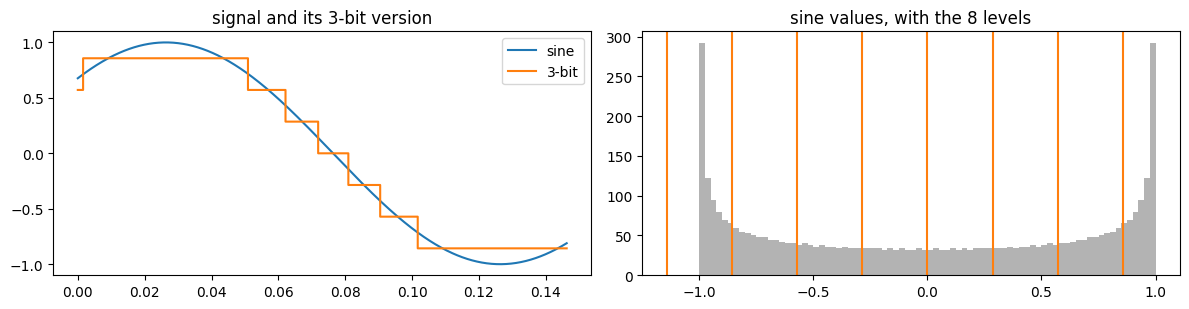

3 bits: S = 0.2857, Z = 4, levels = [-1.143 -0.857 -0.571 -0.286  0.     0.286  0.571  0.857]


In [13]:
# given: one quantizer, drawn
x = SIGNALS["sine"]
q, S, Z = quantize(x, 3)
x_hat = dequantize(q, S, Z)
levels = S * (np.arange(2 ** 3) - Z)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(t[:600], x[:600], label="sine"); ax[0].step(t[:600], x_hat[:600], where="mid", label="3-bit")
ax[0].set_title("signal and its 3-bit version"); ax[0].legend()
ax[1].hist(x, bins=80, color="0.7"); [ax[1].axvline(l, color="C1") for l in levels]
ax[1].set_title("sine values, with the 8 levels"); plt.tight_layout(); plt.show()
print(f"3 bits: S = {S:.4f}, Z = {Z:.0f}, levels = {np.round(levels, 3)}")

### 1b — Sweep the bits

📝 **Predict.** By how many dB should the SNR rise for each extra bit? (One bit halves `S`; what does
halving `S` do to the error power?) Which signal, sine or noise, will have the higher SNR at the same bit
width, and why? (Look at their min and max next to their mean square.)

Every additional bit doubles the number of quantization levels, which halves the scale (S). The expected quantization error is MSE = S²/12. When the scale is halved, the new error becomes (S/2)²/12 = S²/48. Comparing this with the original error S²/12, we get a ratio of 1/4. Therefore, the error power decreases to one-quarter with every additional bit.

The SNR improvement can be calculated as 10 × log10(4) = 6.02 dB. Hence, SNR should increase by approximately 6 dB per additional bit.

The sine wave is expected to have a higher SNR than Gaussian noise at the same bit-width.

From our measurements, the sine has a range of:

1.000 - (-1.000) = 2.000

The noise has a range of:

3.460 - (-3.491) = 6.951

Using S = (r_max - r_min)/(2^b - 1), at 3 bits the sine's scale is 2/7 = 0.2857, whereas the noise's scale is 6.951/7 = 0.9930.

Since MSE is approximately S²/12, the expected error for the sine is (0.2857)²/12 = 0.00680, while for the noise it is (0.9930)²/12 = 0.08217.

Although the noise has a higher mean square (1.009 compared to 0.500), its much larger range results in greater quantization error and consequently lower SNR. Therefore, the sine is expected to have a higher SNR at the same bit-width.


sine: SNR rises 6.35 dB per bit (fitted over 3-8 bits)
  1 bits   S 2.00000   MSE 5.000e-01   S^2/12 3.333e-01   ratio 1.50   SNR   0.0 dB
  2 bits   S 0.66667   MSE 4.801e-02   S^2/12 3.704e-02   ratio 1.30   SNR  10.2 dB
  3 bits   S 0.28571   MSE 8.131e-03   S^2/12 6.803e-03   ratio 1.20   SNR  17.9 dB
  4 bits   S 0.13333   MSE 1.680e-03   S^2/12 1.481e-03   ratio 1.13   SNR  24.7 dB
  5 bits   S 0.06452   MSE 3.792e-04   S^2/12 3.469e-04   ratio 1.09   SNR  31.2 dB
  6 bits   S 0.03175   MSE 8.948e-05   S^2/12 8.398e-05   ratio 1.07   SNR  37.5 dB
  7 bits   S 0.01575   MSE 2.162e-05   S^2/12 2.067e-05   ratio 1.05   SNR  43.6 dB
  8 bits   S 0.00784   MSE 5.294e-06   S^2/12 5.126e-06   ratio 1.03   SNR  49.8 dB

noise: SNR rises 6.23 dB per bit (fitted over 3-8 bits)
  1 bits   S 6.95073   MSE 1.009e+00   S^2/12 4.026e+00   ratio 0.25   SNR   0.0 dB
  2 bits   S 2.31691   MSE 4.391e-01   S^2/12 4.473e-01   ratio 0.98   SNR   3.6 dB
  3 bits   S 0.99296   MSE 8.174e-02   S^2/12 8

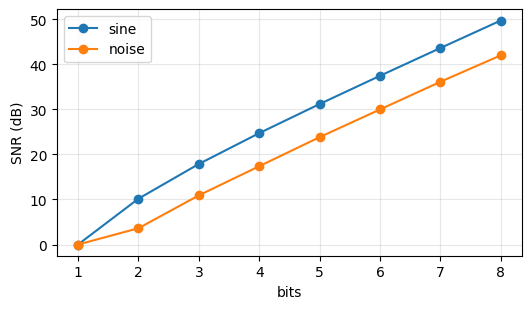

In [14]:
# harness (given): MSE against S^2 / 12, and SNR, for both signals at every bit width
sweep = {}
for name, x in SIGNALS.items():
    rows = []
    for b in BITS:
        q, S, Z = quantize(x, b)
        x_hat = dequantize(q, S, Z)
        rows.append(dict(bits=b, S=float(S), mse=float(np.mean((x_hat - x) ** 2)),
                         s2_over_12=float(S ** 2 / 12), snr=float(snr_db(x, x_hat))))
    slope = float(np.polyfit([r["bits"] for r in rows if r["bits"] >= 3],
                             [r["snr"] for r in rows if r["bits"] >= 3], 1)[0])
    sweep[name] = dict(rows=rows, slope_db_per_bit=slope)
    print(f"\n{name}: SNR rises {slope:.2f} dB per bit (fitted over 3-8 bits)")
    for r in rows:
        print(f"  {r['bits']} bits   S {r['S']:.5f}   MSE {r['mse']:.3e}   S^2/12 {r['s2_over_12']:.3e}"
              f"   ratio {r['mse'] / r['s2_over_12']:.2f}   SNR {r['snr']:5.1f} dB")

plt.figure(figsize=(6, 3.2))
for name in SIGNALS:
    plt.plot(BITS, [r["snr"] for r in sweep[name]["rows"]], "o-", label=name)
plt.xlabel("bits"); plt.ylabel("SNR (dB)"); plt.legend(); plt.grid(alpha=.3); plt.show()
RESULTS["sweep"] = sweep

📝 **Explain.** Where does `MSE ≈ S² / 12` hold, and at which bit widths does it break down, and why? What
is the dB-per-bit rule you measured, in one sentence? Why does the noise lose to the sine at every width?

The relationship MSE ≈ S²/12 holds well at 4–8 bits for both signals. This can be verified by comparing the measured MSE with the theoretical value S²/12. For the sine at 3 bits, the ratio is:

Ratio = Measured MSE / (S²/12)

= 0.008131 / 0.006803

= 1.20

At 8 bits:

= 0.000005294 / 0.000005126

= 1.03

For noise at 1 bit, the ratio is 1.009 / 4.026 = 0.25, whereas at 8 bits it is approximately 1.02. The approximation becomes less accurate at lower bit-widths because the quantization errors are not uniformly distributed across the quantization interval.

Every additional bit halves the scale (S), reducing the quantization error power to one-quarter. Therefore, the theoretical SNR improvement is:

SNR improvement = 10 × log10(4)

= 6.02 dB

Our measured SNR slopes are 6.35 dB per bit for the sine and 6.23 dB per bit for noise, which are close to the theoretical prediction of approximately 6 dB per bit.

The noise has a lower SNR than the sine at every bit-width because its larger range produces a larger quantization step and consequently greater quantization error. For example, at 3 bits, the sine has a range of:

Range = 1.000 - (-1.000) = 2.000

Its scale is:

S = (1.000 - (-1.000)) / (2³ - 1)

= 2 / 7

= 0.2857

For noise:

Range = 3.460 - (-3.491) = 6.951

S = 6.951 / 7

= 0.9930

To compare their SNR, we use:

SNR = 10 × log10(Signal Power / Error Power)

For sine:

= 10 × log10(0.500 / 0.008131)

= 17.9 dB

For noise:

= 10 × log10(1.009 / 0.08174)

= 10.9 dB

Although noise has higher signal power, its larger quantization error results in a lower SNR. This is why the sine consistently achieves a higher SNR than noise at every bit-width.

### 1c — One outlier

Lecture 21/22 §5: one large value sets `S` for everything that shares it. The harness sets **one** sample of
the sine to 20 and quantizes at 8 bits twice: once with one `(S, Z)` for the whole signal, and once in
**blocks of 64 samples**, each with its own `(S, Z)`. It measures the SNR of every sample **except** the
outlier.

📝 **Predict.** The range grows from about 2 to about 21. By how many dB should the SNR of the other 4,095
samples drop? (`S` grows with the range; use your dB-per-bit rule.) What will blocks of 64 recover?

<br>
<br>

The range of the sine signal increases from approximately 2 to 21 when one sample is replaced with 20. Since the quantization scale `S` is proportional to the signal range, the new scale becomes approximately 10.5 times larger:

`S_new / S_old = 21 / 2 = 10.5`

The quantization error power is approximately:

`MSE ≈ S² / 12`

Therefore, increasing the scale by 10.5 increases the quantization error power by a factor of:

`MSE_new / MSE_old = (10.5)²`

Using the SNR formula:

`SNR_dB = 10 × log10(P_signal / P_error)`

The signal power of the other samples remains approximately unchanged because the outlier is excluded from the SNR measurement. Hence, the expected SNR drop is:

`SNR drop = 10 × log10((10.5)²)`

`= 20 × log10(10.5)`

`≈ 20.42 dB`

This is equivalent to losing approximately:

`20.42 / 6.02 ≈ 3.4 bits`

I expect blocks of 64 samples to recover most of this lost SNR. Each block has its own scale and zero point, so the outlier only increases the quantization range of the block containing it. The remaining blocks can use smaller scales suited to their local ranges, preserving much better precision for most samples. The trade-off is the additional storage required for the scale and zero point of every block.

In [15]:
# harness (given): one outlier, per-signal vs per-block scales, 8 bits
x = SIGNALS["sine"].copy()
spike = int(rng.integers(N)); x[spike] = 20.0
rest = np.arange(N) != spike

clean_hat = dequantize(*quantize(SIGNALS["sine"], 8))
whole_hat = dequantize(*quantize(x, 8))
block_hat = np.concatenate([dequantize(*quantize(x[i:i + 64], 8)) for i in range(0, N, 64)])

range_ratio = (max(x.max(), 0) - min(x.min(), 0)) / (max(SIGNALS["sine"].max(), 0) - min(SIGNALS["sine"].min(), 0))
outlier = dict(snr_clean=float(snr_db(SIGNALS["sine"], clean_hat)),
               snr_whole=float(snr_db(x[rest], whole_hat[rest])),
               snr_blocks=float(snr_db(x[rest], block_hat[rest])),
               range_ratio=float(range_ratio))
outlier["drop_db"] = outlier["snr_clean"] - outlier["snr_whole"]
print(f"8 bits, no outlier:              SNR {outlier['snr_clean']:5.1f} dB")
print(f"8 bits, outlier, one (S, Z):     SNR of the other samples {outlier['snr_whole']:5.1f} dB"
      f"   (drop {outlier['drop_db']:.1f} dB, range grew {range_ratio:.1f}x)")
print(f"8 bits, outlier, blocks of 64:   SNR of the other samples {outlier['snr_blocks']:5.1f} dB")
RESULTS["outlier"] = outlier

8 bits, no outlier:              SNR  49.8 dB
8 bits, outlier, one (S, Z):     SNR of the other samples  29.9 dB   (drop 19.8 dB, range grew 10.5x)
8 bits, outlier, blocks of 64:   SNR of the other samples  48.1 dB


📝 **Explain.** Turn your drop into bits: how many of the 8 bits did one outlier waste? Why do blocks of 64
get almost all of them back, and what do the blocks cost in storage (Lecture 21/22 §5's bits-per-weight
formula, with an fp16 `S` and `Z` per block)?

<br>
<br>

The outlier caused an SNR drop of 19.8 dB. Since each additional quantization bit provides approximately 6.02 dB of SNR, the number of bits wasted is:

Bits wasted = SNR drop / 6.02\
\= 19.8 / 6.02\
≈ 3.29 bits

Therefore, one outlier effectively wastes about 3.3 of the 8 bits, leaving the other samples with precision comparable to roughly 4.7 bits.

Blocks of 64 recover almost all the lost precision because each block has its own scale (`S`) and zero point (`Z`). The outlier increases the range only in the block containing it, while the other blocks can use smaller scales suited to their local ranges. The measured SNR improves from 29.9 dB to 48.1 dB, recovering 18.2 dB of the 19.8 dB loss.

However, storing separate scale and zero-point values for every block requires additional memory. With 8-bit quantized values and an fp16 scale and fp16 zero point per block, the storage cost is:

Bits per weight = b + (bits for S + bits for Z) / block size\
\= 8 + (16 + 16) / 64\
\= 8 + 0.5\
\= 8.5 bits per weight

Thus, block-wise quantization increases storage from 8 to 8.5 bits per value, an overhead of 0.5 bits per value, while recovering nearly all the SNR lost due to the outlier.

---
## Part 2 — Quantize a small model

### The model

A one-hidden-layer network that reads an 8×8 handwritten digit (64 pixels) and outputs one of 10 classes.
The cell trains it in about a second; after that it is **only two weight matrices and two bias vectors**:

```
hidden = relu(x @ W1 + b1)       # W1: (64, 64)
logits = hidden @ W2 + b2        # W2: (64, 10)
predicted digit = argmax(logits)
```

`W1[:, j]`, **column `j`**, holds the 64 weights that produce hidden unit `j`. A column is one **output
channel** (scikit-learn stores weights as `(in, out)`).

You quantize **only the weights**; the biases stay in float. Nothing is retrained.

In [16]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

X, y = load_digits(return_X_y=True)
X = X / 16.0                                     # pixels 0..16 -> 0..1
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED % 10_000)
clf = MLPClassifier(hidden_layer_sizes=(64,), max_iter=600, random_state=SEED % 10_000).fit(X_tr, y_tr)
(W1, W2), (b1, b2) = clf.coefs_, clf.intercepts_

def accuracy(W1, W2):
    hidden = np.maximum(X_te @ W1 + b1, 0)
    return float(np.mean((hidden @ W2 + b2).argmax(1) == y_te))

FLOAT_ACC = accuracy(W1, W2)
print(f"W1 {W1.shape}, W2 {W2.shape} | float test accuracy {FLOAT_ACC:.3f} "
      f"(sklearn's own: {clf.score(X_te, y_te):.3f}) on {len(y_te)} test digits")
for name, w in [("W1", W1), ("W2", W2)]:
    print(f"{name}: range [{w.min():.3f}, {w.max():.3f}], 99% of |w| below {np.percentile(np.abs(w), 99):.3f}")

W1 (64, 64), W2 (64, 10) | float test accuracy 0.967 (sklearn's own: 0.967) on 540 test digits
W1: range [-1.071, 0.812], 99% of |w| below 0.658
W2: range [-1.326, 1.235], 99% of |w| below 1.045


### 2a — Per-tensor vs per-channel

**Per-tensor** uses your `quantize` on a whole matrix: one `(S, Z)`. **Per-channel** gives every column its
own `(S, Z)` (Lecture 21/22 §5).

📝 **Predict.** At 8 bits, how much accuracy do you expect to lose? Below how many bits do you expect it to
fall apart? Will per-channel help, and at which widths will you be able to see it?

<br>
<br>

At 8 bits, I expect the model to retain most of its original accuracy (96.7%) because the quantization steps are relatively small compared with the weight ranges. As the bit width decreases, the quantization error will increase, which may change some predictions, especially when two classes have similar output scores.

I expect per-channel quantization to perform better than per-tensor quantization because each column gets its own scale and zero point. This helps columns with smaller weight ranges use the available quantization levels more effectively. I expect this difference to become more noticeable at lower bit widths.

However, I cannot predict the exact bit width at which accuracy will start dropping significantly. We will need to compare the measured accuracies to find that out.

 bits   per-tensor acc  (W1 SNR)    per-channel acc  (W1 SNR)
  1        0.111     (  0.0 dB)       0.159     (  0.2 dB)
  2        0.850     (  3.4 dB)       0.876     (  7.7 dB)
  3        0.941     ( 10.6 dB)       0.967     ( 14.9 dB)
  4        0.972     ( 17.3 dB)       0.965     ( 21.5 dB)
  5        0.967     ( 23.5 dB)       0.965     ( 27.8 dB)
  6        0.967     ( 29.8 dB)       0.965     ( 34.1 dB)
  7        0.965     ( 35.7 dB)       0.967     ( 40.0 dB)
  8        0.967     ( 41.9 dB)       0.967     ( 46.2 dB)


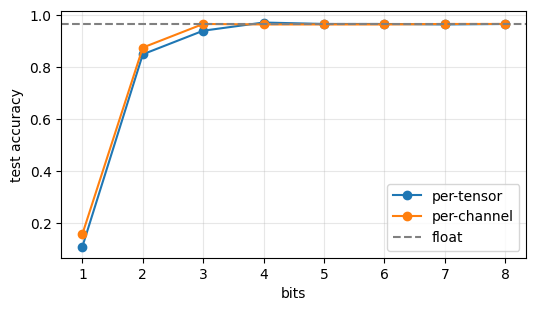

In [17]:
def quantize_per_channel(w, bits):
    '''w: (in, out) weight matrix. Quantize each column with its own (S, Z) using your quantize, decode it,
       and return the decoded matrix, same shape as w.'''
    w_hat = np.zeros_like(w, dtype=float)

    for j in range(w.shape[1]):
      column = w[:, j]

      # Each output channel needs its own quantisation parameters.
      q, S, Z = quantize(column, bits)

      # Decode the column before placing it in the output matrix.
      decoded_column = dequantize(q, S, Z)

      w_hat[:, j] = decoded_column

    return w_hat


# harness (given): accuracy and weight SNR at every bit width, both granularities
def per_tensor(w, bits): return dequantize(*quantize(w, bits))

model = dict(float_acc=FLOAT_ACC, sklearn_acc=float(clf.score(X_te, y_te)), tensor={}, channel={})
for gran, fn in [("tensor", per_tensor), ("channel", quantize_per_channel)]:
    for b in BITS:
        W1h, W2h = fn(W1, b), fn(W2, b)
        model[gran][b] = dict(acc=accuracy(W1h, W2h), snr_w1=float(snr_db(W1, W1h)),
                              max_levels_per_column=int(max(len(np.unique(W1h[:, j])) for j in range(W1.shape[1]))))
print(" bits   per-tensor acc  (W1 SNR)    per-channel acc  (W1 SNR)")
for b in BITS:
    t_, c_ = model["tensor"][b], model["channel"][b]
    print(f"  {b}        {t_['acc']:.3f}     ({t_['snr_w1']:5.1f} dB)       {c_['acc']:.3f}     ({c_['snr_w1']:5.1f} dB)")

plt.figure(figsize=(6, 3.2))
for gran in ("tensor", "channel"):
    plt.plot(BITS, [model[gran][b]["acc"] for b in BITS], "o-", label=f"per-{gran}")
plt.axhline(FLOAT_ACC, color="0.5", ls="--", label="float")
plt.xlabel("bits"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()
RESULTS["model"] = model

[link text](https://)📝 **Explain.** Where did accuracy fall apart, and why does per-channel hold on longer? Use the printed
ranges: which columns set the per-tensor `S`?

<br>

Accuracy falls apart mainly at 1 bit, where per-tensor accuracy is only 0.111 and per-channel accuracy is 0.159. At 2 bits, accuracy improves to 0.850 and 0.876, respectively. At 3 bits, per-channel reaches the original float accuracy of 0.967, while per-tensor reaches 0.941. From 4 bits onwards, both methods maintain almost the full accuracy.

The reason is that per-tensor quantization uses one scale for the entire weight matrix. The scale is calculated using:

`S = (r_max - r_min) / (2^bits - 1)`

For W1, the printed range is:

`r_min = -1.071`\
`r_max = 0.812`

At 8 bits:

`S = (0.812 - (-1.071)) / 255`

`S = 1.883 / 255 ≈ 0.00738`

The columns containing the minimum (-1.071) and maximum (0.812) weights determine this shared scale. Columns with smaller weight ranges must use the same scale, which means they cannot use all the available quantization levels effectively.

Per-channel quantization solves this by calculating a separate scale for each column:

`S_j = (r_max,j - r_min,j) / (2^bits - 1)`

This allows each column to use its available quantization levels more effectively. As a result, W1 has higher SNR with per-channel quantization. For example, at 3 bits, its SNR improves from 10.6 dB to 14.9 dB, and accuracy improves from 0.941 to 0.967.

Therefore, per-channel quantization preserves weight precision better, particularly at lower bit widths, and helps the model maintain its classification accuracy.

### 2b — Connect the two parts

📝 **Explain (the paragraph that carries this lab).** At 3 bits the weights' SNR is low, a level you would
call badly distorted for the sine in Part 1, yet the classifier barely notices. Why can a model tolerate
error that a signal metric calls large? (Think about what the model's output is: an `argmax`.) What does
that say about judging a quantized model by its weight error alone, and what should you measure instead?

<br>

At 3 bits, the weight SNR is only 10.6 dB for per-tensor and 14.9 dB for per-channel quantization. In Part 1, a low SNR meant that the reconstructed sine signal was noticeably distorted. However, the classifier still achieves 0.941 and 0.967 accuracy, respectively. This happens because the classifier does not need to reconstruct the original weights perfectly. It only needs to predict the correct class.

The model calculates logits for each class and selects the class with the highest value:

`predicted_class = argmax(logits)`

Even if quantization changes the logits slightly, the prediction remains unchanged as long as the correct class still has the highest score.

For example:

```
Original logits:  [2.1, 0.8, 0.3]
Predicted class:  0

Quantized logits: [1.9, 0.9, 0.4]
Predicted class:  0
```

Although the values have changed, the predicted class remains the same. A prediction changes only when quantization error is large enough to change the ranking of the class scores.

Therefore, weight SNR alone is not sufficient to judge a quantized model. A model can have considerable weight error but still produce correct predictions. Instead, we should measure test accuracy after quantization, along with other task-specific metrics such as precision, recall and F1-score when appropriate.

This shows that quantization quality should ultimately be judged by its effect on the model's actual task, not just by how closely the quantized weights match the original weights.

---
## Submit

Run this last. It writes `submission_lab19_22b_<roll>.json`. Submit **two files**: that JSON and this
executed notebook with every 📝 cell filled.

In [18]:
env = dict(platform=platform.platform(), python=sys.version.split()[0],
           numpy=np.__version__, sklearn=sklearn.__version__, seed=SEED, cycles=CYCLES)
sub = dict(roll=ROLL_NUMBER, name=NAME, env=env, results=RESULTS)
out = Path(f"submission_lab19_22b_{ROLL_NUMBER}.json")
out.write_text(json.dumps(sub, indent=2))
print("wrote", out, "| parts:", list(RESULTS))
assert set(RESULTS) >= {"sweep", "outlier", "model"}, "run every part before exporting"

wrote submission_lab19_22b_202518035.json | parts: ['sweep', 'outlier', 'model']
